# Street-tree cooling model: effect of a tree row on canyon air temperature at peak heat

**Purpose.** Estimate how much a row of street trees changes the **canyon-average air temperature** of an urban street at the **hottest hour of a day**, and break the effect down into its physical components.

**Type of model.** A *reduced-order, physics-based box model* with empirical coefficients. It is built from standard elements of urban climatology (surface energy balance, single-layer street-canyon ventilation, big-leaf crown energy balance). It is not a replacement for a validated 3D model (PALM-4U, ENVI-met), but it is transparent, fast, and gives physically consistent order-of-magnitude estimates with uncertainty ranges.

**Contents**
1. Scientific basis
2. Assumptions and limitations
3. Inputs and outputs
4. Model code
5. Example: base case
6. (Optional) Weather forcing from Open-Meteo
7. Scenarios
8. Sensitivity: wind × transpiration, and crown cover
9. Monte Carlo uncertainty
10. Interpretation and references

**Requirements:** Python ≥ 3.8, `numpy`, `matplotlib` (optionally internet access for section 6).

## 1. Scientific basis

### 1.1 Energy conservation (surface energy balance)
Every surface (road, walls, tree crown) obeys the first law of thermodynamics:

$$Q^* = Q_H + Q_E + \Delta Q_S$$

Absorbed net radiation $Q^*$ is split into sensible heat $Q_H$ (warms the air), latent heat $Q_E$ (evaporation / transpiration) and heat storage $\Delta Q_S$ (Oke 1982; Oke et al. 2017).

### 1.2 Street canyon as a well-mixed box (single-layer canopy concept)
Canyon air is treated as one well-mixed volume. At steady state, sensible heat released into the canyon equals heat exported through the roof-level opening:

$$Q_{H,total} = \rho c_p \, w_e \, W \,(T_{can}-T_{above})$$

with the **exchange velocity** $w_e = c_e\,U$ ($c_e \approx 0.1$ for skimming flow; Barlow & Belcher 2002; Bentham & Britter 2003; Hamlyn & Britter 2005). This is the same idea used in single-layer urban canopy models (TEB, Masson 2000; SLUCM, Kusaka et al. 2001).

### 1.3 Tree crown as a "big leaf"
* Radiation passing through the crown: **Beer–Lambert law** $\tau = e^{-k\,LAI}$ (Monsi & Saeki 1953).
* Crown net radiation: $R_{n,c} = (1-\alpha_c)(1-\tau)K_\downarrow + L_c$.
* Crown sensible heat = net radiation − transpiration: $Q_{H,c} = R_{n,c} - \lambda E_c$ (no storage in leaves).
* Transpiration $\lambda E_c$ is prescribed from sap-flow measurements or estimated with **Priestley–Taylor** (Priestley & Taylor 1972) with a water-stress factor.

### 1.4 Shading of the road
Under the crown the road receives only diffuse light and the light transmitted through the crown. The sensible heat it no longer releases is the reduction in absorbed direct radiation × $f_H$, the fraction of absorbed energy leaving asphalt as sensible heat at peak hour (empirical, ≈ 0.4–0.6).

### 1.5 Reduced ventilation (drag)
Crowns slow down the flow in the canyon (wind tunnel: Gromke & Ruck 2007, 2009; multilayer modelling: Krayenhoff et al. 2015). Simple parameterisation:
$$w_{e1} = w_{e0}\,(1-c_d\,\lambda_c)$$

### 1.6 Result: tree effect on canyon air temperature
$$
\delta T =
\underbrace{\frac{\Delta Q_{shade}}{\rho c_p w_{e1} W}}_{\text{shade (cooling)}}
+\underbrace{\frac{\Delta Q_{crown}}{\rho c_p w_{e1} W}}_{\text{crown heat (warming)}}
+\underbrace{\Delta T_0\left(\frac{w_{e0}}{w_{e1}}-1\right)}_{\text{reduced ventilation (warming)}}
$$
with (per metre of street)
$$a_c = \frac{\pi d_c^2}{4s},\quad \lambda_c=\frac{a_c}{W},\quad
\Delta Q_{shade} = -a_c f_H (1-\alpha_r)(1-\tau)K_{dir},\quad
\Delta Q_{crown} = a_c (R_{n,c}-\lambda E_c).$$

The transpiration contribution alone (relative to a hypothetical non-transpiring crown) is $-a_c\lambda E_c/(\rho c_p w_{e1} W)$.

| Part | Basis |
|---|---|
| Energy conservation, radiation, box heat budget | first principles |
| Beer–Lambert, Priestley–Taylor | physically based with fitted parameters |
| $c_e$, $f_H$, $c_d$, $\lambda E_c$, $\Delta T_0$ | **empirical coefficients → main uncertainty** |

## 2. Assumptions and limitations

* **Steady state at peak hour** – no time history; heat stored earlier in the day is only implicitly represented through $f_H$ and $\Delta T_0$.
* **Canyon-average** air temperature – air directly under crowns can be locally 2–3× cooler than the canyon average.
* **Shadow falls on the road** (high sun). Shading of walls/façades is ignored (→ cooling slightly underestimated).
* **No along-street advection**, no intersections, no anthropogenic heat changes.
* **No leaf heat storage, fixed crown longwave** $L_c$ → for drought-stressed (hot) crowns the warming term is likely **overestimated**.
* **Wind**: $U$ is the wind speed at roof level. Weather-service / reanalysis 10 m wind refers to open terrain; in dense cities roof-level wind is often lower (use a reduction factor ≈ 0.5–1).
* Does **not** give surface temperature or thermal comfort (mean radiant temperature, UTCI). Those effects of shade are much larger than the air-temperature effect and need a radiation model (e.g. SOLWEIG).

**Use it for:** order-of-magnitude estimates, scenario comparison, explaining mechanisms, uncertainty ranges.
**Do not use it for:** precise point predictions, design decisions without validation.

## 3. Inputs and outputs

### 3.1 Inputs (`ModelInputs`)
All fluxes in W m⁻², lengths in m, wind in m s⁻¹, temperatures in K (differences) or °C.

| Name | Symbol | Unit | Default | Typical range | Source |
|---|---|---|---|---|---|
| `W` | $W$ | m | 20 | 10–40 | map / field |
| `H` | $H$ | m | 15 | 5–30 | map / field (used for reporting H/W only) |
| `K_down` | $K_\downarrow$ | W m⁻² | 850 | 600–950 (peak, clear sky) | Open-Meteo `shortwave_radiation` |
| `f_dif` | $f_{dif}$ | – | 0.15 | 0.1–0.3 | Open-Meteo `diffuse_radiation / shortwave_radiation` |
| `U` | $U$ | m s⁻¹ | 1.0 | 0.3–4 | roof-level wind (≈ 0.5–1 × 10 m wind) |
| `alb_road` | $\alpha_r$ | – | 0.10 | 0.05–0.2 | asphalt ≈ 0.1 |
| `f_H` | $f_H$ | – | 0.5 | 0.4–0.6 | literature (asphalt energy balance) |
| `d_crown` | $d_c$ | m | 17 | 6–24 | tree inventory; the map's tree sizes are 6 / 17 / 24 m |
| `spacing` | $s$ | m | 20 | 6–30 | tree inventory; at least `d_crown`, or crowns overlap |
| `LAI` | $LAI$ | m² m⁻² | 4 | 2–6 | literature / LAI meter |
| `k_ext` | $k$ | – | 0.5 | 0.4–0.7 | literature |
| `alb_crown` | $\alpha_c$ | – | 0.2 | 0.15–0.25 | literature |
| `L_crown` | $L_c$ | W m⁻² | −70 | −100 … −50 | literature |
| `LE_crown` | $\lambda E_c$ | W m⁻² crown | 380 | 300–450 watered; 50–150 drought | sap flow / Priestley–Taylor |
| `c_e` | $c_e$ | – | 0.10 | 0.05–0.2 | canyon ventilation studies |
| `c_d` | $c_d$ | – | 0.3 | 0–0.4 | drag parameterisation |
| `dT0` | $\Delta T_0$ | K | 1.5 | 1–2 | canyon air excess without trees (measured or literature) |
| `T_above` | $T_{above}$ | °C | 32 | – | Open-Meteo `temperature_2m` at peak hour |

### 3.2 Outputs (`ModelOutputs`)

| Name | Unit | Meaning |
|---|---|---|
| `a_c` | m² m⁻¹ | crown projected area per metre of street |
| `crown_cover` | – | crown cover fraction of street width $\lambda_c$ |
| `tau` | – | crown light transmission |
| `Rn_crown` | W m⁻² | crown net radiation |
| `dQ_shade`, `dQ_crown` | W m⁻¹ | change in sensible heat into canyon due to shading / crown |
| `we0`, `we1` | m s⁻¹ | exchange velocity without / with trees |
| `dT_shade` | K | air-temperature contribution of shading (negative = cooling) |
| `dT_crown` | K | contribution of crown sensible heat (positive = warming) |
| `dT_transpiration` | K | part of the cooling that is due to transpiration (diagnostic, already inside `dT_crown`) |
| `dT_ventilation` | K | contribution of reduced ventilation (positive = warming) |
| **`dT_total`** | K | **net tree effect on canyon-average air temperature** |
| `T_can_no_trees`, `T_can_trees` | °C | canyon air temperature without / with trees |
| `warnings` | list | plausibility warnings |

## 4. Model code

In [1]:
import math
from dataclasses import dataclass, field, asdict, replace
from typing import List

import numpy as np
import matplotlib.pyplot as plt

RHO_CP = 1200.0      # volumetric heat capacity of air [J m-3 K-1]
LAMBDA_V = 2.45e6    # latent heat of vaporisation [J kg-1]

In [2]:
@dataclass
class ModelInputs:
    """Inputs of the street-tree canyon cooling model (see table in section 3.1)."""
    # street geometry
    W: float = 20.0           # street width between building facades [m]
    H: float = 15.0           # mean building height [m] (reporting only)
    # weather at peak hour
    K_down: float = 850.0     # global shortwave radiation [W m-2]
    f_dif: float = 0.15       # diffuse fraction of K_down [-]
    U: float = 1.0            # wind speed at roof level [m s-1]
    T_above: float = 32.0     # air temperature above roof level [degC]
    # road
    alb_road: float = 0.10    # road albedo [-]
    f_H: float = 0.5          # fraction of absorbed radiation released as sensible heat [-]
    # trees
    d_crown: float = 17.0     # crown diameter [m] (the map's medium tree)
    spacing: float = 20.0     # distance between trees along the street [m]
    LAI: float = 4.0          # leaf area index [m2 m-2]
    k_ext: float = 0.5        # light extinction coefficient [-]
    alb_crown: float = 0.20   # crown albedo [-]
    L_crown: float = -70.0    # crown net longwave radiation [W m-2]
    LE_crown: float = 380.0   # transpiration as latent heat flux per crown area [W m-2]
    # canyon ventilation
    c_e: float = 0.10         # exchange velocity / roof-level wind [-]
    c_d: float = 0.3          # ventilation reduction per unit crown cover [-]
    dT0: float = 1.5          # canyon air excess over air above roofs, no trees [K]


@dataclass
class ModelOutputs:
    """Outputs of the model (see table in section 3.2)."""
    a_c: float
    crown_cover: float
    tau: float
    Rn_crown: float
    dQ_shade: float
    dQ_crown: float
    we0: float
    we1: float
    dT_shade: float
    dT_crown: float
    dT_transpiration: float
    dT_ventilation: float
    dT_total: float
    T_can_no_trees: float
    T_can_trees: float
    warnings: List[str] = field(default_factory=list)

In [3]:
def le_from_sapflow(sapflow_L_per_h: float, crown_area_m2: float) -> float:
    """Convert a measured tree sap flow [L h-1] into latent heat flux per crown area [W m-2].

    Assumes 1 L water = 1 kg and that sap flow equals transpiration at the peak hour.
    Example: 20 L/h for a 50 m2 crown -> ~272 W m-2.
    """
    return LAMBDA_V * sapflow_L_per_h / 3600.0 / crown_area_m2


def le_priestley_taylor(Rn: float, T_air_C: float, beta: float = 1.0, alpha_pt: float = 1.26) -> float:
    """Priestley-Taylor estimate of crown transpiration [W m-2].

    Rn      : crown net radiation [W m-2]
    T_air_C : air temperature [degC] (sets the slope of the saturation vapour pressure curve)
    beta    : water-stress factor, 1 = well watered, ~0.2-0.4 = drought-stressed
    """
    es = 0.6108 * math.exp(17.27 * T_air_C / (T_air_C + 237.3))      # kPa
    s = 4098.0 * es / (T_air_C + 237.3) ** 2                          # kPa K-1
    gamma = 0.066                                                     # kPa K-1 (sea level)
    return beta * alpha_pt * s / (s + gamma) * Rn

In [4]:
def run_model(p: ModelInputs) -> ModelOutputs:
    """Street-tree canyon cooling model (steady state, peak hour, per metre of street).

    Equations (section 1):
      a_c       = pi d_c^2 / (4 s)                 crown area per metre of street
      lambda_c  = a_c / W                          crown cover fraction
      tau       = exp(-k LAI)                      crown transmission (Beer-Lambert)
      dQ_shade  = -a_c f_H (1-alb_r)(1-tau) K_dir  less sensible heat from shaded road
      Rn_c      = (1-alb_c)(1-tau) K_down + L_c    crown net radiation
      dQ_crown  = a_c (Rn_c - LE_c)                sensible heat released by crown
      we0 = c_e U ,  we1 = we0 (1 - c_d lambda_c)  exchange velocity without / with trees
      dT = dQ_shade/(rho cp we1 W) + dQ_crown/(rho cp we1 W) + dT0 (we0/we1 - 1)
    """
    warn = []
    K_dir = (1.0 - p.f_dif) * p.K_down

    a_c = math.pi * p.d_crown ** 2 / 4.0 / p.spacing
    lam = a_c / p.W
    if p.d_crown > p.spacing:
        warn.append("Crowns overlap (d_crown > spacing): crown area is overestimated.")
    if lam > 1.0:
        warn.append("Crown cover > 100 % of street width: check d_crown, spacing, W.")
    tau = math.exp(-p.k_ext * p.LAI)

    dQ_shade = -a_c * p.f_H * (1.0 - p.alb_road) * (1.0 - tau) * K_dir
    Rn_c = (1.0 - p.alb_crown) * (1.0 - tau) * p.K_down + p.L_crown
    if p.LE_crown > Rn_c * 1.3:
        warn.append("LE_crown well above crown net radiation: only possible with strong advection.")
    dQ_crown = a_c * (Rn_c - p.LE_crown)

    we0 = p.c_e * p.U
    red = 1.0 - p.c_d * lam
    if red <= 0.1:
        warn.append("Ventilation reduction factor too small (c_d * crown_cover too large); clipped to 0.1.")
        red = 0.1
    we1 = we0 * red
    if we0 < 0.03:
        warn.append("Very low exchange velocity (calm): steady-state box assumption is weak.")

    D = RHO_CP * we1 * p.W        # heat export capacity [W m-1 K-1]
    dT_shade = dQ_shade / D
    dT_crown = dQ_crown / D
    dT_transp = -a_c * p.LE_crown / D
    dT_vent = p.dT0 * (we0 / we1 - 1.0)
    dT = dT_shade + dT_crown + dT_vent

    return ModelOutputs(a_c, lam, tau, Rn_c, dQ_shade, dQ_crown, we0, we1,
                        dT_shade, dT_crown, dT_transp, dT_vent, dT,
                        p.T_above + p.dT0, p.T_above + p.dT0 + dT, warn)


def report(p: ModelInputs, o: ModelOutputs) -> None:
    """Print inputs and outputs in a readable form."""
    print(f"Street: W = {p.W:.0f} m, H = {p.H:.0f} m (H/W = {p.H / p.W:.2f}),  U = {p.U} m/s,  K_down = {p.K_down} W/m2")
    print(f"Trees : d_crown = {p.d_crown} m every {p.spacing} m, LAI = {p.LAI}, LE_crown = {p.LE_crown} W/m2")
    print(f"  crown area per m street a_c   = {o.a_c:6.2f} m2/m   (crown cover {100 * o.crown_cover:.0f} %)")
    print(f"  crown transmission tau        = {o.tau:6.3f}")
    print(f"  crown net radiation Rn_c      = {o.Rn_crown:6.0f} W/m2")
    print(f"  dQ shade / dQ crown           = {o.dQ_shade:6.0f} / {o.dQ_crown:+.0f} W per m street")
    print(f"  exchange velocity we0 -> we1  = {o.we0:.3f} -> {o.we1:.3f} m/s")
    print("  --- air temperature contributions [K] ---")
    print(f"  shade                         = {o.dT_shade:+.2f}")
    print(f"  crown sensible heat           = {o.dT_crown:+.2f}   (transpiration share: {o.dT_transpiration:+.2f})")
    print(f"  reduced ventilation           = {o.dT_ventilation:+.2f}")
    print(f"  NET tree effect dT_total      = {o.dT_total:+.2f} K")
    print(f"  canyon air: {o.T_can_no_trees:.1f} degC without trees -> {o.T_can_trees:.1f} degC with trees")
    for w in o.warnings:
        print("  WARNING:", w)

## 5. Example: base case

Street 20 m wide, 15 m high; clear summer peak hour (850 W m⁻², 15 % diffuse); roof-level wind 1 m s⁻¹; well-watered trees with 17 m crowns (the map's medium tree) every 20 m.

In [5]:
base = ModelInputs()
out = run_model(base)
report(base, out)

Street: W = 20 m, H = 15 m (H/W = 0.75),  U = 1.0 m/s,  K_down = 850.0 W/m2
Trees : d_crown = 17.0 m every 20.0 m, LAI = 4.0, LE_crown = 380.0 W/m2
  crown area per m street a_c   =  11.35 m2/m   (crown cover 57 %)
  crown transmission tau        =  0.135
  crown net radiation Rn_c      =    518 W/m2
  dQ shade / dQ crown           =  -3190 / +1566 W per m street
  exchange velocity we0 -> we1  = 0.100 -> 0.083 m/s
  --- air temperature contributions [K] ---
  shade                         = -1.60
  crown sensible heat           = +0.79   (transpiration share: -2.17)
  reduced ventilation           = +0.31
  NET tree effect dT_total      = -0.51 K
  canyon air: 33.5 degC without trees -> 33.0 degC with trees


### Estimating transpiration (`LE_crown`)
Two helpers are provided. Use measured sap flow when available (most reliable), otherwise Priestley–Taylor with a water-stress factor `beta`.

In [6]:
crown_area = math.pi * base.d_crown ** 2 / 4
print(f"From sap flow 20 L/h, crown {crown_area:.0f} m2   : LE = {le_from_sapflow(20, crown_area):.0f} W/m2")
print(f"Priestley-Taylor, well watered (beta=1.0)  : LE = {le_priestley_taylor(out.Rn_crown, base.T_above, 1.0):.0f} W/m2")
print(f"Priestley-Taylor, drought      (beta=0.3)  : LE = {le_priestley_taylor(out.Rn_crown, base.T_above, 0.3):.0f} W/m2")

From sap flow 20 L/h, crown 227 m2   : LE = 60 W/m2
Priestley-Taylor, well watered (beta=1.0)  : LE = 524 W/m2
Priestley-Taylor, drought      (beta=0.3)  : LE = 157 W/m2


## 6. (Optional) Weather forcing from Open-Meteo

Fetches hourly data for a location and date from the free [Open-Meteo archive API](https://open-meteo.com/) (no API key) and picks the hottest hour. Set `USE_OPEN_METEO = True` to use it. Without internet the base-case values are used.

Note: the 10 m wind refers to open terrain; it is multiplied by `WIND_FACTOR` to approximate roof-level wind in the city.

In [7]:
USE_OPEN_METEO = False
LAT, LON = 48.137, 11.575          # Munich city centre (example)
DATE = "2025-07-02"                # a heatwave day (example)
WIND_FACTOR = 0.7                  # 10 m open-terrain wind -> roof-level urban wind

def fetch_peak_hour(lat, lon, date):
    """Return weather at the hottest hour of `date` from the Open-Meteo archive."""
    import json, urllib.request
    url = ("https://archive-api.open-meteo.com/v1/archive"
           f"?latitude={lat}&longitude={lon}&start_date={date}&end_date={date}"
           "&hourly=temperature_2m,shortwave_radiation,diffuse_radiation,wind_speed_10m"
           "&wind_speed_unit=ms&timezone=auto")
    with urllib.request.urlopen(url, timeout=20) as r:
        h = json.load(r)["hourly"]
    i = int(np.argmax(h["temperature_2m"]))
    sw = h["shortwave_radiation"][i]
    return dict(time=h["time"][i], T=h["temperature_2m"][i], K_down=sw,
                f_dif=h["diffuse_radiation"][i] / sw if sw > 0 else 1.0,
                U10=h["wind_speed_10m"][i])

forcing = base
if USE_OPEN_METEO:
    try:
        w = fetch_peak_hour(LAT, LON, DATE)
        print("Peak hour:", w)
        forcing = replace(base, T_above=w["T"], K_down=w["K_down"], f_dif=w["f_dif"],
                          U=max(w["U10"] * WIND_FACTOR, 0.3))
    except Exception as e:
        print("Open-Meteo request failed, using base case:", e)

report(forcing, run_model(forcing))

Street: W = 20 m, H = 15 m (H/W = 0.75),  U = 1.0 m/s,  K_down = 850.0 W/m2
Trees : d_crown = 17.0 m every 20.0 m, LAI = 4.0, LE_crown = 380.0 W/m2
  crown area per m street a_c   =  11.35 m2/m   (crown cover 57 %)
  crown transmission tau        =  0.135
  crown net radiation Rn_c      =    518 W/m2
  dQ shade / dQ crown           =  -3190 / +1566 W per m street
  exchange velocity we0 -> we1  = 0.100 -> 0.083 m/s
  --- air temperature contributions [K] ---
  shade                         = -1.60
  crown sensible heat           = +0.79   (transpiration share: -2.17)
  reduced ventilation           = +0.31
  NET tree effect dT_total      = -0.51 K
  canyon air: 33.5 degC without trees -> 33.0 degC with trees


## 7. Scenarios

Each scenario changes one or two inputs relative to the base case. The stacked bars show the three physical components; the black dot is the net effect.

scenario                    cover   shade   crown    vent     NET  [K]
Base (U=1, watered)          0.57   -1.60   +0.79   +0.31   -0.51
Calm (U=0.5)                 0.57   -3.20   +1.57   +0.31   -1.32
Windy (U=2)                  0.57   -0.80   +0.39   +0.31   -0.10
Drought (LE=100)             0.57   -1.60   +2.38   +0.31   +1.09
No drag (c_d=0)              0.57   -1.33   +0.65   +0.00   -0.68
Dense row (s=17 m)           0.67   -1.96   +0.96   +0.38   -0.62
Small trees (d=6 m)          0.07   -0.17   +0.08   +0.03   -0.05
Large trees (d=24 m, s=24 m)   0.94   -3.08   +1.51   +0.59   -0.98
Narrow street (W=12 m)       0.95   -3.09   +1.52   +0.59   -0.98


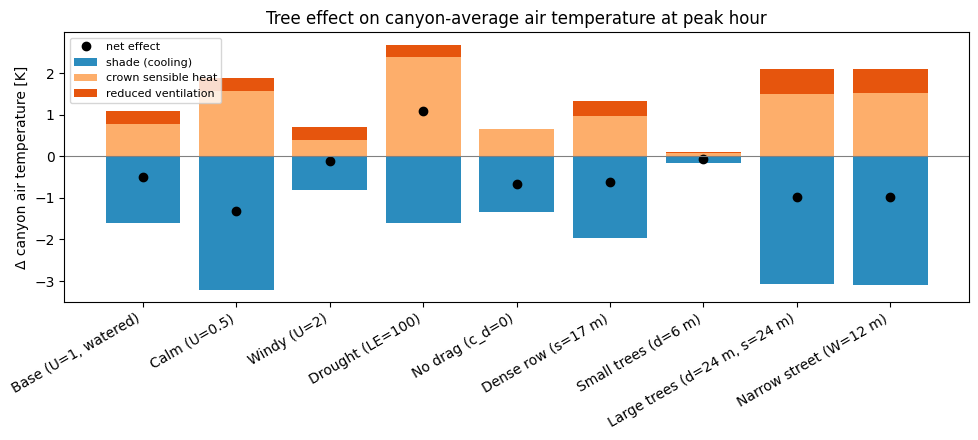

In [8]:
scenarios = {
    "Base (U=1, watered)":      {},
    "Calm (U=0.5)":             {"U": 0.5},
    "Windy (U=2)":              {"U": 2.0},
    "Drought (LE=100)":         {"LE_crown": 100.0},
    "No drag (c_d=0)":          {"c_d": 0.0},
    "Dense row (s=17 m)":       {"spacing": 17.0},
    "Small trees (d=6 m)":      {"d_crown": 6.0},
    "Large trees (d=24 m, s=24 m)": {"d_crown": 24.0, "spacing": 24.0},
    "Narrow street (W=12 m)":   {"W": 12.0},
}

results = {name: run_model(replace(base, **chg)) for name, chg in scenarios.items()}

print(f"{'scenario':26s} {'cover':>6s} {'shade':>7s} {'crown':>7s} {'vent':>7s} {'NET':>7s}  [K]")
for name, o in results.items():
    print(f"{name:26s} {o.crown_cover:6.2f} {o.dT_shade:+7.2f} {o.dT_crown:+7.2f} {o.dT_ventilation:+7.2f} {o.dT_total:+7.2f}")
    for wmsg in o.warnings:
        print("   WARNING:", wmsg)

names = list(results)
x = np.arange(len(names))
sh = np.array([results[n].dT_shade for n in names])
cr = np.array([results[n].dT_crown for n in names])
ve = np.array([results[n].dT_ventilation for n in names])
net = np.array([results[n].dT_total for n in names])

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.bar(x, sh, color="#2b8cbe", label="shade (cooling)")
pos_base = np.zeros_like(cr)
ax.bar(x, cr, bottom=pos_base, color="#fdae6b", label="crown sensible heat")
ax.bar(x, ve, bottom=pos_base + cr, color="#e6550d", label="reduced ventilation")
ax.plot(x, net, "ko", label="net effect")
ax.axhline(0, color="grey", lw=0.8)
ax.set_xticks(x); ax.set_xticklabels(names, rotation=30, ha="right")
ax.set_ylabel("Δ canyon air temperature [K]")
ax.set_title("Tree effect on canyon-average air temperature at peak hour")
ax.legend(fontsize=8, loc="upper left")
plt.tight_layout(); plt.show()

### 7.1 Export for the street map

The scenario results are written to `data/canyon_scenarios.json`. The street map (`index.html`) reads this file and shows the scenarios under **Canyon air temperature** in the scenario panel, where users can pick one and compare it with the others. Re-run this notebook after changing the model or the scenarios.

In [9]:
import json, re
from pathlib import Path

EXPORT_PATH = Path("data/canyon_scenarios.json")

def scenario_id(name: str) -> str:
    return re.sub(r"[^a-z0-9]+", "-", name.split("(")[0].lower()).strip("-")

export = {
    "_about": "Generated by street_tree_cooling_model.ipynb (section 7). Do not edit by hand; re-run the notebook.",
    "title": "Tree effect on canyon-average air temperature at peak hour",
    "unit": "K",
    "base": asdict(base),
    "scenarios": [
        {"id": scenario_id(name), "label": name, "changes": chg,
         "inputs": asdict(replace(base, **chg)), "outputs": asdict(results[name])}
        for name, chg in scenarios.items()
    ],
}
EXPORT_PATH.write_text(json.dumps(export, indent=1, ensure_ascii=False) + "\n", encoding="utf-8")
print(f"Wrote {len(export['scenarios'])} scenarios to {EXPORT_PATH}")

Wrote 9 scenarios to data/canyon_scenarios.json


## 8. Sensitivity analysis

### 8.1 Wind × transpiration
The two most influential controls are ventilation (roof-level wind) and how much the trees transpire (water supply).

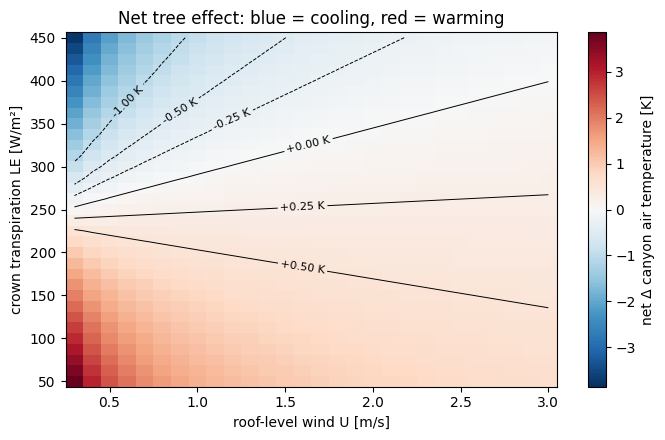

In [10]:
U_vals = np.linspace(0.3, 3.0, 28)
LE_vals = np.linspace(50, 450, 33)
Z = np.array([[run_model(replace(base, U=u, LE_crown=le)).dT_total for u in U_vals] for le in LE_vals])

fig, ax = plt.subplots(figsize=(7, 4.5))
lim = np.nanmax(np.abs(Z))
pc = ax.pcolormesh(U_vals, LE_vals, Z, cmap="RdBu_r", vmin=-lim, vmax=lim, shading="auto")
cs = ax.contour(U_vals, LE_vals, Z, levels=[-1, -0.5, -0.25, 0, 0.25, 0.5], colors="k", linewidths=0.7)
ax.clabel(cs, fmt="%+.2f K", fontsize=8)
fig.colorbar(pc, label="net Δ canyon air temperature [K]")
ax.set_xlabel("roof-level wind U [m/s]")
ax.set_ylabel("crown transpiration LE [W/m²]")
ax.set_title("Net tree effect: blue = cooling, red = warming")
plt.tight_layout(); plt.show()

### 8.2 Crown cover (tree spacing)

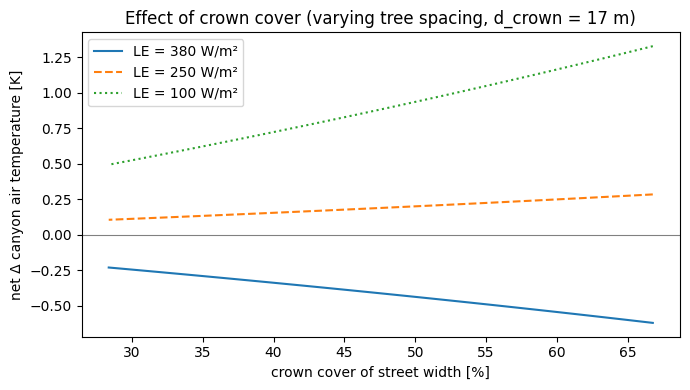

In [11]:
spacings = np.linspace(base.d_crown, 40, 47)  # from crowns touching to wide gaps
outs = [run_model(replace(base, spacing=s)) for s in spacings]
cover = [o.crown_cover * 100 for o in outs]

fig, ax = plt.subplots(figsize=(7, 4))
for le, ls in [(380, "-"), (250, "--"), (100, ":")]:
    ax.plot(cover, [run_model(replace(base, spacing=s, LE_crown=le)).dT_total for s in spacings],
            ls, label=f"LE = {le} W/m²")
ax.axhline(0, color="grey", lw=0.8)
ax.set_xlabel("crown cover of street width [%]")
ax.set_ylabel("net Δ canyon air temperature [K]")
ax.set_title(f"Effect of crown cover (varying tree spacing, d_crown = {base.d_crown:g} m)")
ax.legend(); plt.tight_layout(); plt.show()

## 9. Monte Carlo uncertainty

The empirical coefficients are uncertain. We sample them uniformly within literature ranges (wind, radiation and tree geometry kept at the scenario values) and report the median and 5–95 % range. Change `MC_RANGES` or `scenario` to analyse your own case.

Net tree effect: median -0.37 K, 90 % range [-1.41, +0.12] K, P(cooling) = 88 %


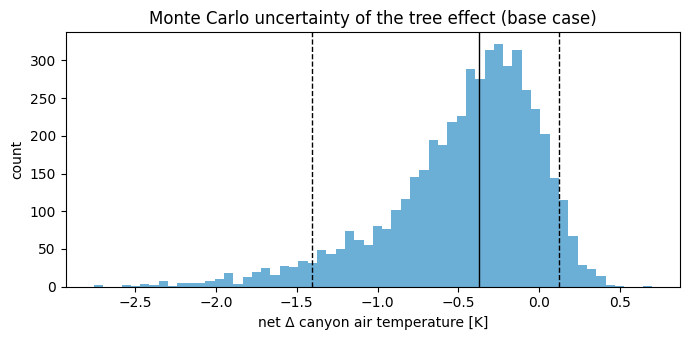

In [12]:
MC_RANGES = {            # uniform ranges of uncertain coefficients
    "c_e":      (0.05, 0.20),
    "f_H":      (0.40, 0.60),
    "c_d":      (0.20, 0.40),
    "LE_crown": (300., 450.),   # well-watered; use (50, 150) for drought
    "dT0":      (1.0, 2.0),
    "L_crown":  (-100., -50.),
    "k_ext":    (0.40, 0.60),
    "LAI":      (3.0, 5.0),
}

def monte_carlo(p: ModelInputs, ranges: dict, n: int = 5000, seed: int = 1) -> np.ndarray:
    """Return n samples of dT_total with the coefficients in `ranges` drawn uniformly."""
    rng = np.random.default_rng(seed)
    draws = {k: rng.uniform(lo, hi, n) for k, (lo, hi) in ranges.items()}
    return np.array([run_model(replace(p, **{k: v[i] for k, v in draws.items()})).dT_total
                     for i in range(n)])

scenario = base
mc = monte_carlo(scenario, MC_RANGES)
p5, p50, p95 = np.percentile(mc, [5, 50, 95])
print(f"Net tree effect: median {p50:+.2f} K, 90 % range [{p5:+.2f}, {p95:+.2f}] K, "
      f"P(cooling) = {np.mean(mc < 0) * 100:.0f} %")

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(mc, bins=60, color="#6baed6")
for v in (p5, p50, p95):
    ax.axvline(v, color="k", ls="--" if v != p50 else "-", lw=1)
ax.set_xlabel("net Δ canyon air temperature [K]"); ax.set_ylabel("count")
ax.set_title("Monte Carlo uncertainty of the tree effect (base case)")
plt.tight_layout(); plt.show()

## 10. Interpretation and references

### How to read the results
* `dT_total` is the change of **canyon-average** air temperature at the peak hour. Locally under the crowns, air cooling can be 2–3× larger.
* **Plausibility check:** for well-watered trees on calm days, literature reports roughly 0.2–1 K canyon-average and up to ~1–2 K under-canopy air cooling. Results far outside this range → check `c_e`, `U` and `LE_crown` first (the most sensitive inputs).
* The **drought case** can show slight warming; the magnitude is probably overestimated (fixed crown longwave, no leaf storage). Interpret as "little or no air cooling".
* The air-temperature effect is much smaller than the effect of shade on **surface temperature** (≈ 15–20 K) and **mean radiant temperature** (≈ 20–30 K), which matter more for human heat stress. Model those with a radiation model (e.g. SOLWEIG in UMEP/QGIS).
* Always report **ranges** (section 9), not single numbers.

### Next steps for a more rigorous analysis
1. Calibrate `LE_crown` with sap-flow data and `dT0`, `c_e` with canyon measurements.
2. Extend to a diurnal cycle (loop over hours, add heat storage).
3. Validate against PALM-4U / ENVI-met / Urban Tethys-Chloris simulations or field measurements.

### References
* Barlow, J.F. & Belcher, S.E. (2002) A wind tunnel model for quantifying fluxes in the urban boundary layer. *Boundary-Layer Meteorology* 104, 131–150.
* Bentham, T. & Britter, R. (2003) Spatially averaged flow within obstacle arrays. *Atmospheric Environment* 37, 2037–2043.
* Gromke, C. & Ruck, B. (2007, 2009) Influence of trees on the dispersion of pollutants in an urban street canyon. *Atmospheric Environment* 41; *Boundary-Layer Meteorology* 131.
* Hamlyn, D. & Britter, R. (2005) A numerical study of the flow field and exchange processes within a canopy of urban-type roughness. *Atmospheric Environment* 39, 3243–3254.
* Krayenhoff, E.S. et al. (2015) A multi-layer urban canopy meteorological model with trees (BEP-Tree). *Boundary-Layer Meteorology* 156, 157–189.
* Kusaka, H. et al. (2001) A simple single-layer urban canopy model for atmospheric models. *Boundary-Layer Meteorology* 101, 329–358.
* Masson, V. (2000) A physically-based scheme for the urban energy budget in atmospheric models. *Boundary-Layer Meteorology* 94, 357–397.
* Meili, N. et al. (2021) Tree effects on urban microclimate. *Urban Forestry & Urban Greening* 58, 126970.
* Monsi, M. & Saeki, T. (1953) Über den Lichtfaktor in den Pflanzengesellschaften. *Japanese Journal of Botany* 14, 22–52.
* Oke, T.R. (1982) The energetic basis of the urban heat island. *QJRMS* 108, 1–24; Oke, T.R. et al. (2017) *Urban Climates*. Cambridge University Press.
* Priestley, C.H.B. & Taylor, R.J. (1972) On the assessment of surface heat flux and evaporation using large-scale parameters. *Monthly Weather Review* 100, 81–92.
* Rahman, M.A. et al. (2020) Traits of trees for cooling urban heat islands: a meta-analysis. *Building and Environment* 170, 106606.